# Predictive Analysis (Classification)

Four classifiers (Logistic Regression, SVM, Decision Tree, KNN) tuned with 10-fold `GridSearchCV` on an 80/20 split. Target: **Class** (1 = first stage landed).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import warnings; warnings.filterwarnings("ignore")

In [2]:
d=pd.read_csv("data/spacex_wrangled.csv")
def block(b):
    return 0 if "v1.0" in b else 1 if "v1.1" in b else 2 if "FT" in b else 4 if "B4" in b else 5 if "B5" in b else 3
d["Block"]=d.Booster_Version.map(block)
X=pd.concat([d[["FlightNumber","PAYLOAD_MASS__KG_","Block"]],pd.get_dummies(d.Orbit,prefix="Orbit"),pd.get_dummies(d.Launch_Site,prefix="Site")],axis=1).astype(float)
y=d["Class"].values
print(X.shape)
X_std=StandardScaler().fit_transform(X)
X_train,X_test,y_train,y_test=train_test_split(X_std,y,test_size=0.2,random_state=2)
print(len(y_train),len(y_test))

(101, 15)
80 21


In [3]:
grids={
 "Logistic Regression":(LogisticRegression(max_iter=1000),{"C":[0.01,0.1,1]}),
 "SVM":(SVC(),{"kernel":["linear","rbf","poly","sigmoid"],"C":np.logspace(-3,3,5),"gamma":np.logspace(-3,3,5)}),
 "Decision Tree":(DecisionTreeClassifier(random_state=0),{"criterion":["gini","entropy"],"splitter":["best","random"],"max_depth":[2*n for n in range(1,10)],"max_features":["sqrt"],"min_samples_leaf":[1,2,4],"min_samples_split":[2,5,10]}),
 "KNN":(KNeighborsClassifier(),{"n_neighbors":list(range(1,11)),"algorithm":["auto"],"p":[1,2]})}
results={}; fitted={}
for name,(model,grid) in grids.items():
    gs=GridSearchCV(model,grid,cv=10).fit(X_train,y_train); fitted[name]=gs
    results[name]={"cv_accuracy":gs.best_score_,"test_accuracy":gs.score(X_test,y_test),"best_params":gs.best_params_}
    print(f"{name:20s} CV={gs.best_score_:.3f}  test={gs.score(X_test,y_test):.3f}")

Logistic Regression  CV=0.762  test=0.667


SVM                  CV=0.775  test=0.619


Decision Tree        CV=0.787  test=0.714


KNN                  CV=0.775  test=0.714


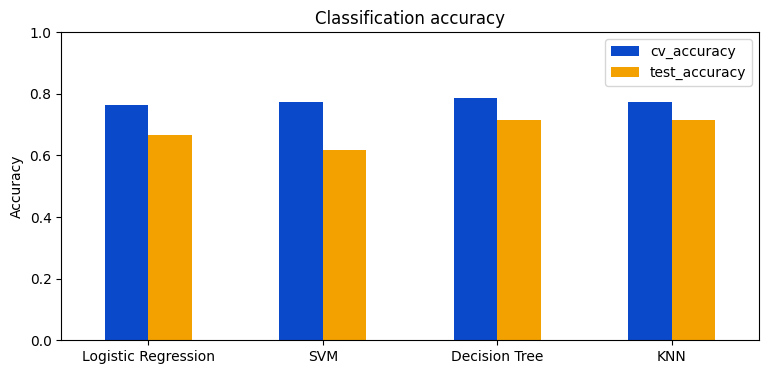

,cv_accuracy,test_accuracy
Logistic Regression,0.762,0.667
SVM,0.775,0.619
Decision Tree,0.788,0.714
KNN,0.775,0.714


In [4]:
res=pd.DataFrame(results).T[["cv_accuracy","test_accuracy"]].astype(float)
res.plot.bar(figsize=(9,4),color=["#0B49CB","#F2A100"]); plt.ylim(0,1); plt.ylabel("Accuracy"); plt.xticks(rotation=0); plt.title("Classification accuracy"); plt.show(); res.round(3)

Best model by CV accuracy: Decision Tree


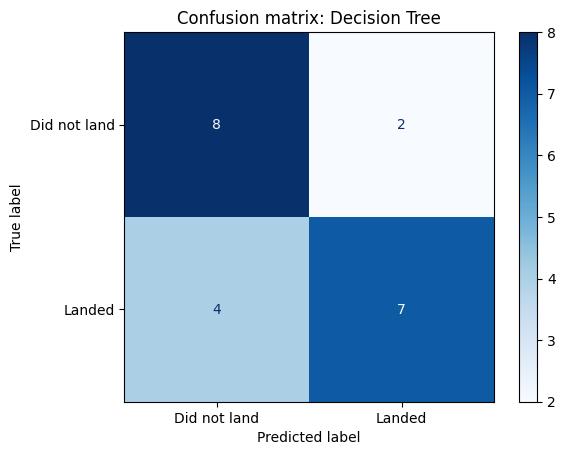

array([[8, 2],
       [4, 7]])

In [5]:
best=res["cv_accuracy"].idxmax(); print("Best model by CV accuracy:",best)
cm=confusion_matrix(y_test,fitted[best].predict(X_test))
ConfusionMatrixDisplay(cm,display_labels=["Did not land","Landed"]).plot(cmap="Blues"); plt.title(f"Confusion matrix: {best}"); plt.show(); cm

**Reading the result:** the test set has only 21 launches, so one launch moves accuracy by about 5 points. Differences between models are within noise; Decision Tree is preferred for its best cross-validated score.